# Fase 02 : Análisis estadístico y descriptivo
**Institución:** Universidad Católica Boliviana "San Pablo"  
**Programa:** Maestría en Ciencia de Datos  
**Autor:** Carlos Andrés Pérez Guzmán  
**Fecha:** Septiembre 2026  

---
**Entorno y Objetivos del Notebook**
> **Nota:** Descripción de los datos con los que se va a trabajar

* **Fase del Proyecto:** Segunda fase
* **Core Tech Stack:** `Python` (Programación general para ciencia de datos)
---

<h3 style="color:#05856d">1. Librerías</h3>
<hr>

In [1]:
import polars as pl
import polars.selectors as cs
import s_01_functions as fn_01
from pyprojroot import here

<h3 style="color:#05856d">2. Carga de información</h3>
<hr>

Carga de datos limpios

In [2]:
df_01 = pl.read_parquet(source = here()/'01_cleaned_data'/'df_01.parquet')
df_01.glimpse()

Rows: 1602961
Columns: 11
$ bottle_volume_ml  <enum> 750, 1000, 375, 750, 50, 50, 1750, 1750, 750, 375
$ category_name      <cat> 100% AGAVE TEQUILA, IMPORTED SCHNAPPS, 100% AGAVE TEQUILA, 100% AGAVE TEQUILA, AMERICAN CORDIALS & LIQUEUR, AMERICAN SCHNAPPS, AMERICAN VODKAS, AMERICAN VODKAS, AMERICAN VODKAS, AMERICAN VODKAS
$ im_desc            <cat> PATRON SILVER, RUMPLE MINZE PEPPERMINT SCHNAPPS LIQUEUR, DON JULIO BLANCO, PATRON SILVER, 99 WATERMELON PET MINI, 99 FRUITS MINI, BLUE OX VODKA, HAWKEYE VODKA, HAWKEYE VODKA, NEW AMSTERDAM 80PRF
$ item_no            <i64> 88296, 69947, 87484, 88296, 84393, 101180, 36875, 36308, 36306, 36968
$ ordered_on        <date> 2026-01-01, 2026-01-01, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02
$ pack               <i64> 12, 12, 12, 12, 1, 1, 6, 6, 12, 24
$ period_ordered_on  <cat> 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01
$ product_code       <str> 'PRD_0

<h3 style="color:#05856d">3. Análisis descriptivo</h3>
<hr>

<h4 style="color:#05856d">3.1. Variables categóricas</h4>

In [3]:
# Variables categóricas
df_01.select( (cs.string() | cs.categorical()) - cs.by_name('product_code') ).glimpse()

# Vriables numéricas y de fecha
df_01.select(cs.numeric() | cs.by_name('ordered_on')).glimpse()

Rows: 1602961
Columns: 4
$ category_name     <cat> 100% AGAVE TEQUILA, IMPORTED SCHNAPPS, 100% AGAVE TEQUILA, 100% AGAVE TEQUILA, AMERICAN CORDIALS & LIQUEUR, AMERICAN SCHNAPPS, AMERICAN VODKAS, AMERICAN VODKAS, AMERICAN VODKAS, AMERICAN VODKAS
$ im_desc           <cat> PATRON SILVER, RUMPLE MINZE PEPPERMINT SCHNAPPS LIQUEUR, DON JULIO BLANCO, PATRON SILVER, 99 WATERMELON PET MINI, 99 FRUITS MINI, BLUE OX VODKA, HAWKEYE VODKA, HAWKEYE VODKA, NEW AMSTERDAM 80PRF
$ period_ordered_on <cat> 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01
$ store_no          <cat> 5444, 5444, 4417, 4417, 4417, 4417, 4417, 4417, 4417, 4417

Rows: 1602961
Columns: 5
$ item_no        <i64> 88296, 69947, 87484, 88296, 84393, 101180, 36875, 36308, 36306, 36968
$ ordered_on    <date> 2026-01-01, 2026-01-01, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02
$ pack           <i64> 12, 12, 12, 12, 1, 1, 6, 6, 12, 24
$ sales_bottles

<h5 style="font-weight: bold">Categoría del producto</h5>

Cantidad de órdenes o pedidos

In [4]:
df_01.\
    get_column('category_name').\
    value_counts(name = 'count_0', sort = True).\
    with_columns( (pl.col('count_0') / pl.sum('count_0')).alias('ptc_0') )

category_name,count_0,ptc_0
cat,u32,f64
"""AMERICAN VODKAS""",250602,0.156337
"""CANADIAN WHISKIES""",153704,0.095888
"""STRAIGHT BOURBON WHISKIES""",130974,0.081708
"""WHISKEY LIQUEUR""",117919,0.073563
"""100% AGAVE TEQUILA""",96228,0.060031
…,…,…
"""MEZCAL""",1878,0.001172
"""SPECIAL ORDER ITEMS""",511,0.000319
"""CORN WHISKIES""",287,0.000179


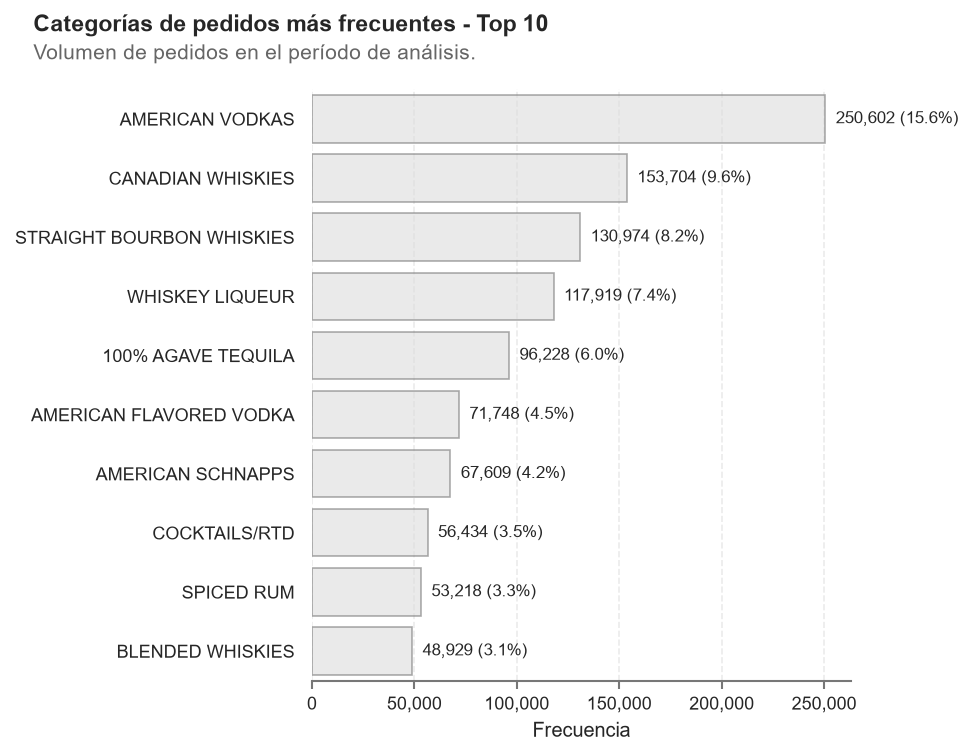

Guardado como: "s_04_01_top_10_categorias_pedidos.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_01_top_10_categorias_pedidos.png')

In [5]:
fn_01.plot_cat_function_01(
    df_param = df_01,
    column_param = 'category_name',
    calculate_param = 'count_',
    top_param = 10,
    suptitle_param = 'Categorías de pedidos más frecuentes - Top 10',
    text_param = 'Volumen de pedidos en el período de análisis.',
    file_param = 's_04_01_top_10_categorias_pedidos.png',
    show_param = True )

Cantidad demandada de botellas

In [6]:
df_01.\
    group_by('category_name').\
    agg(pl.sum('sales_bottles').alias('total_bottles')).\
    with_columns((pl.col('total_bottles') / pl.sum('total_bottles')).alias('ptc_0')).\
    sort( by = ['total_bottles'], descending = [True]) 

category_name,total_bottles,ptc_0
cat,i64,f64
"""AMERICAN VODKAS""",4242900,0.217793
"""WHISKEY LIQUEUR""",3061325,0.157142
"""CANADIAN WHISKIES""",1745364,0.089592
"""STRAIGHT BOURBON WHISKIES""",1105828,0.056764
"""AMERICAN SCHNAPPS""",822353,0.042212
…,…,…
"""NEUTRAL GRAIN SPIRITS""",17811,0.000914
"""MEZCAL""",10445,0.000536
"""CORN WHISKIES""",2100,0.000108


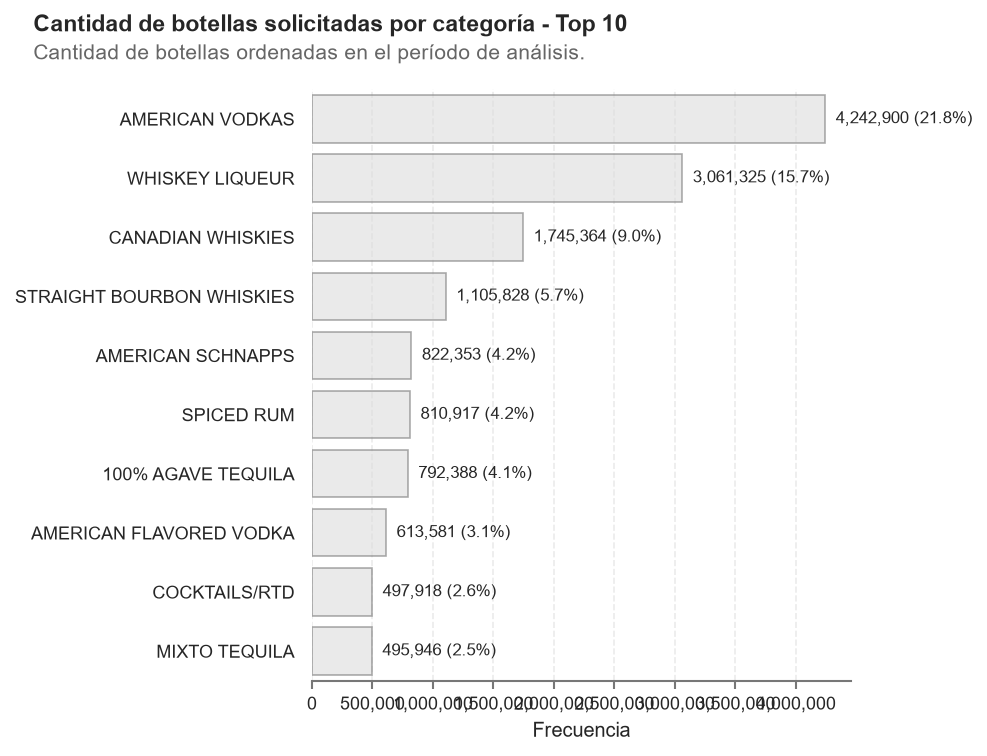

Guardado como: "s_04_02_top_10_categorias_botellas.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_02_top_10_categorias_botellas.png')

In [7]:
fn_01.plot_cat_function_01(
    df_param = df_01,
    column_param = 'category_name',
    calculate_param = 'sum_bottles',
    top_param = 10,
    suptitle_param = 'Cantidad de botellas solicitadas por categoría - Top 10',
    text_param = 'Cantidad de botellas ordenadas en el período de análisis.',
    file_param = 's_04_02_top_10_categorias_botellas.png',
    show_param = True )

<h5 style="font-weight: bold">Descripción del producto</h5>

In [8]:
df_01.\
    get_column('im_desc').\
    value_counts(name = 'count_0', sort = True).\
    with_columns( (pl.col('count_0') / pl.sum('count_0')).alias('ptc_0') )

im_desc,count_0,ptc_0
cat,u32,f64
"""TITOS HANDMADE VODKA""",55487,0.034615
"""FIREBALL CINNAMON WHISKEY""",38089,0.023762
"""BLACK VELVET""",37769,0.023562
"""HAWKEYE VODKA""",35084,0.021887
"""FIREBALL CINNAMON WHISKEY MINI…",22251,0.013881
…,…,…
"""PEERLESS SINGLE BARREL SELECTI…",1,6.2385e-7
"""JEFFERSON BOURBON W/3 BITTERS""",1,6.2385e-7
"""CLEMENT BANA CANNE""",1,6.2385e-7


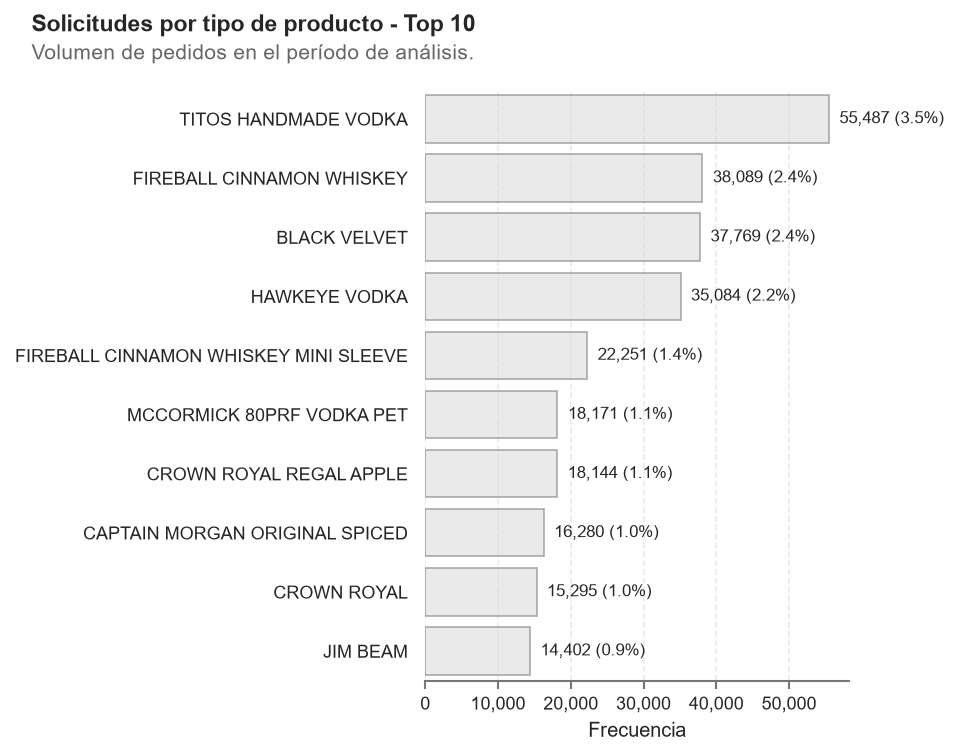

Guardado como: "s_04_03_top_10_productos_pedidos.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_03_top_10_productos_pedidos.png')

In [9]:
fn_01.plot_cat_function_01(
    df_param = df_01,
    column_param = 'im_desc',
    calculate_param = 'count_',
    top_param = 10,
    suptitle_param = 'Solicitudes por tipo de producto - Top 10',
    text_param = 'Volumen de pedidos en el período de análisis.',
    file_param = 's_04_03_top_10_productos_pedidos.png',
    show_param = True )

In [10]:
df_01.\
    group_by('im_desc').\
    agg(pl.sum('sales_bottles').alias('total_bottles')).\
    with_columns((pl.col('total_bottles') / pl.sum('total_bottles')).alias('ptc_0')).\
    sort( by = ['total_bottles'], descending = [True]) 

im_desc,total_bottles,ptc_0
cat,i64,f64
"""FIREBALL CINNAMON WHISKEY""",1948557,0.100022
"""TITOS HANDMADE VODKA""",1133837,0.058201
"""FIREBALL CINNAMON WHISKEY MINI…",605911,0.031102
"""BLACK VELVET""",601712,0.030887
"""HAWKEYE VODKA""",506825,0.026016
…,…,…
"""ABERLOUR 16YR""",1,5.1331e-8
"""KNAPPOGUE CASTLE 12YR USE CODE…",1,5.1331e-8
"""HA OLD FORESTER SINGLE BARREL …",1,5.1331e-8


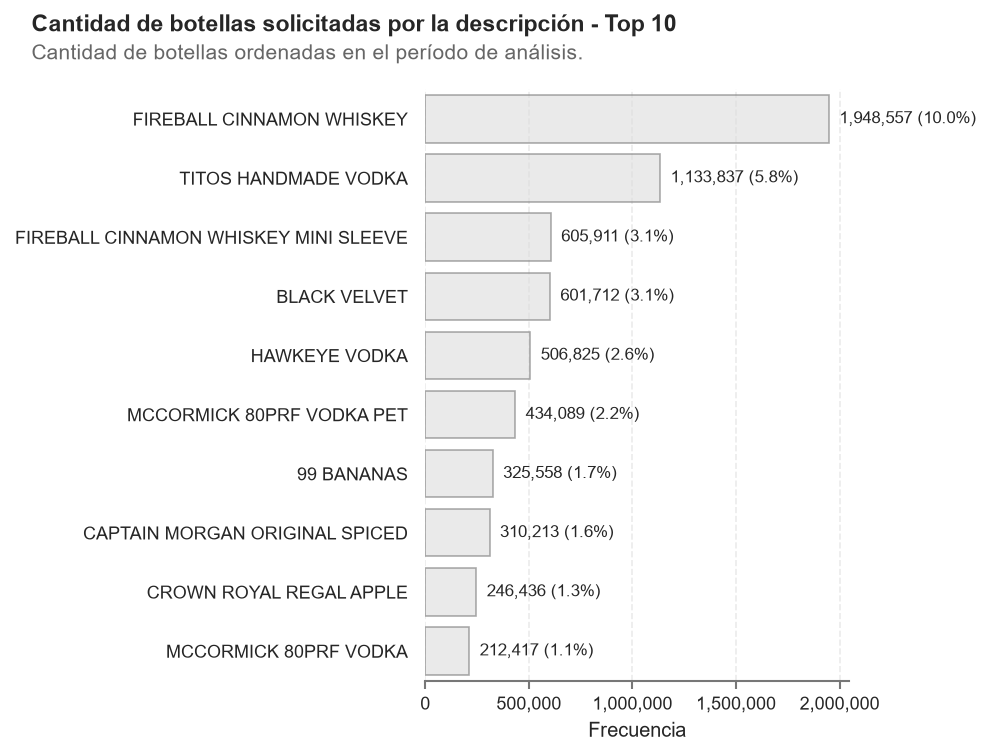

Guardado como: "s_04_04_top_10_productos_botellas.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_04_top_10_productos_botellas.png')

In [11]:
fn_01.plot_cat_function_01(
    df_param = df_01,
    column_param = 'im_desc',
    calculate_param = 'sum_bottles',
    top_param = 10,
    suptitle_param = 'Cantidad de botellas solicitadas por la descripción - Top 10',
    text_param = 'Cantidad de botellas ordenadas en el período de análisis.',
    file_param = 's_04_04_top_10_productos_botellas.png',
    show_param = True )

<h5 style="font-weight: bold">Volumen de botellas</h5>

Aunque medir mililitros puede conducir a variables continuas, las botellas almacenan (en general) volúmenes estándar. Esta característica lleva a que esta variable sea tratada de forma categórica para el caso de estudio.

Dentro del dataframe existen 13 tipos de botellas diferencias por su tamaño.

In [12]:
df_01.get_column('bottle_volume_ml').n_unique()

17

¿Qué tipo de botella fue la más vendida?

In [13]:
df_01.\
    group_by('bottle_volume_ml').\
    agg(pl.sum('sales_bottles')).\
    sort( by = ['sales_bottles'], descending = [True] ).\
    with_columns( (pl.col('sales_bottles') / pl.sum('sales_bottles')).alias('ptc_0') )

bottle_volume_ml,sales_bottles,ptc_0
enum,i64,f64
"""750""",5506405,0.282651
"""1750""",3133946,0.160869
"""375""",2813804,0.144436
"""1000""",2690419,0.138103
"""100""",2478000,0.127199
…,…,…
"""4500""",123,0.000006
"""850""",43,0.000002
"""3750""",27,0.000001


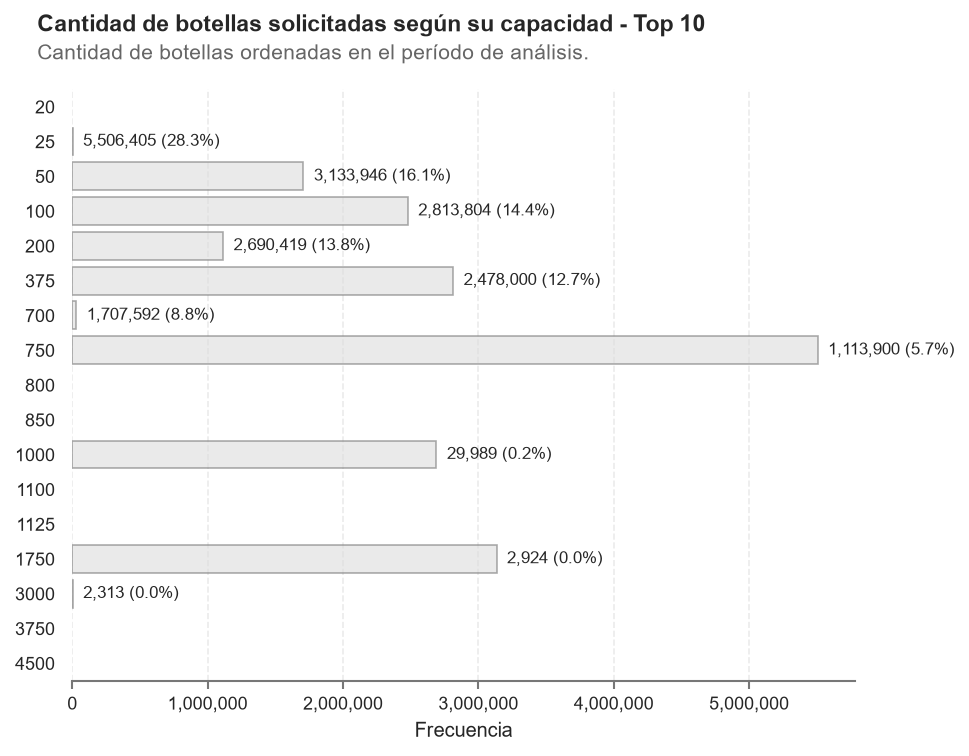

Guardado como: "s_04_05_bottle_volume_ml.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_05_bottle_volume_ml.png')

In [14]:
fn_01.plot_cat_function_01(
    df_param = df_01,
    column_param = 'bottle_volume_ml',
    calculate_param = 'sum_bottles',
    top_param = 10,
    suptitle_param = 'Cantidad de botellas solicitadas según su capacidad - Top 10',
    text_param = 'Cantidad de botellas ordenadas en el período de análisis.',
    file_param = 's_04_05_bottle_volume_ml.png',
    show_param = True )

<h4 style="color:#05856d">3.2. Variables numéricas y de fecha</h4>

In [15]:
# Variables categóricas
df_01.select( (cs.string() | cs.categorical()) - cs.by_name('product_code') ).glimpse()

# Vriables numéricas y de fecha
df_01.select(cs.numeric() | cs.by_name('ordered_on')).glimpse()

Rows: 1602961
Columns: 4
$ category_name     <cat> 100% AGAVE TEQUILA, IMPORTED SCHNAPPS, 100% AGAVE TEQUILA, 100% AGAVE TEQUILA, AMERICAN CORDIALS & LIQUEUR, AMERICAN SCHNAPPS, AMERICAN VODKAS, AMERICAN VODKAS, AMERICAN VODKAS, AMERICAN VODKAS
$ im_desc           <cat> PATRON SILVER, RUMPLE MINZE PEPPERMINT SCHNAPPS LIQUEUR, DON JULIO BLANCO, PATRON SILVER, 99 WATERMELON PET MINI, 99 FRUITS MINI, BLUE OX VODKA, HAWKEYE VODKA, HAWKEYE VODKA, NEW AMSTERDAM 80PRF
$ period_ordered_on <cat> 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01
$ store_no          <cat> 5444, 5444, 4417, 4417, 4417, 4417, 4417, 4417, 4417, 4417

Rows: 1602961
Columns: 5
$ item_no        <i64> 88296, 69947, 87484, 88296, 84393, 101180, 36875, 36308, 36306, 36968
$ ordered_on    <date> 2026-01-01, 2026-01-01, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02
$ pack           <i64> 12, 12, 12, 12, 1, 1, 6, 6, 12, 24
$ sales_bottles

<h5 style="font-weight: bold">Horizonte de análisis</h5>

¿Cuál es el espacio de tiempo en el cual se capturaron los datos?

In [16]:
df_01.get_column('ordered_on').min()

datetime.date(2026, 1, 1)

In [17]:
f_min = df_01.get_column('ordered_on').min()
f_max = df_01.get_column('ordered_on').max()

print(f"Fecha más antigua disponible: {f_min}")
print(f"Fecha más actual disponible: {f_max}")
print(f"Horizonte de tiempo: {(f_max - f_min).days + 1} días")

Fecha más antigua disponible: 2026-01-01
Fecha más actual disponible: 2026-08-31
Horizonte de tiempo: 243 días


<h5 style="font-weight: bold">Demanda de botellas</h5>

*¿Cuál es la distribución de las botellas demandadas por pedido?*

Para dibujar la distribución, primero es necesario agrupar la cantidad de botellas demandadas por día.

In [18]:
aux = df_01.group_by('ordered_on').agg(pl.sum('sales_bottles'))
fn_01.describe_extended(df_param = aux, col_name_param = 'sales_bottles', by_cat_param = None)

statistic,sales_bottles
str,f64
"""count""",192.0
"""nulls""",0.0
"""mean""",101465.208333
"""std""",34643.214523
"""cv""",0.341429
…,…
"""p75""",120869.0
"""p95""",138579.0
"""max""",170571.0


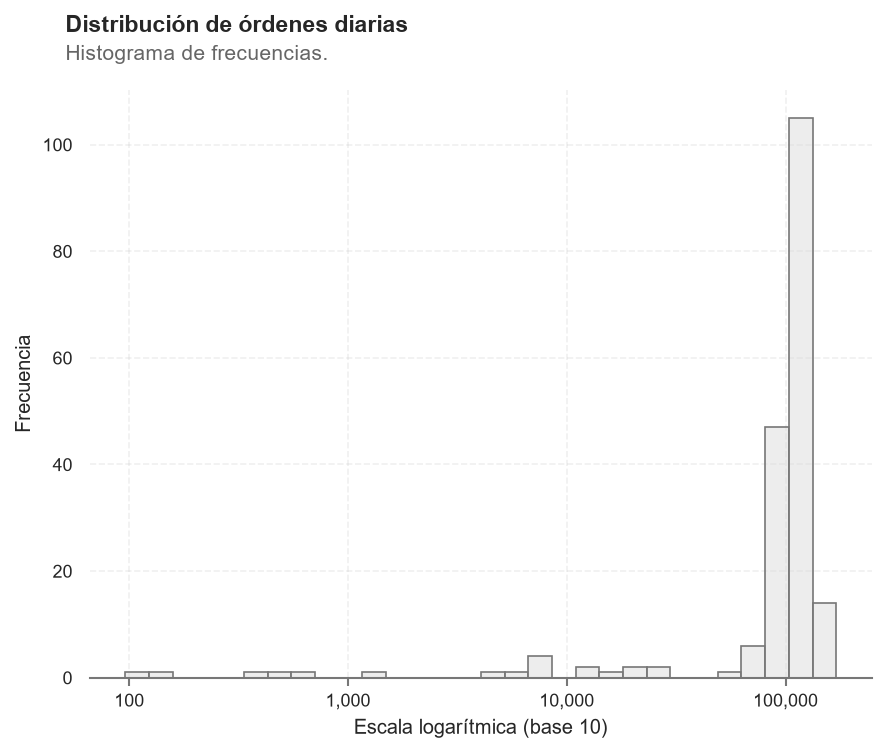

Guardado como: "s_04_06_hist_botellas.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_06_hist_botellas.png')

In [19]:
fn_01.plot_dist_function_02(
    df_param = df_01.group_by('ordered_on').agg(pl.sum('sales_bottles')),
    df_var = 'sales_bottles',
    bins_param = 30,
    suptitle_param = 'Distribución de órdenes diarias',
    text_param = 'Histograma de frecuencias.',
    file_param = 's_04_06_hist_botellas.png',
    show_param = True)


<h5 style="font-weight: bold">Ingresos generados</h5>

*¿Cuál es la distribución de los ingresos por pedido diario?*

Para dibujar la distribución primero es necesario agrupar la cantidad de ingresos por día

In [20]:
aux = df_01.group_by('ordered_on').agg(pl.sum('sales_dollars'))
fn_01.describe_extended(df_param = aux, col_name_param = 'sales_dollars', by_cat_param = None)

statistic,sales_dollars
str,f64
"""count""",192.0
"""nulls""",0.0
"""mean""",1.3848e6
"""std""",483892.203286
"""cv""",0.349434
…,…
"""p75""",1.6584e6
"""p95""",1.8937e6
"""max""",2.2595e6


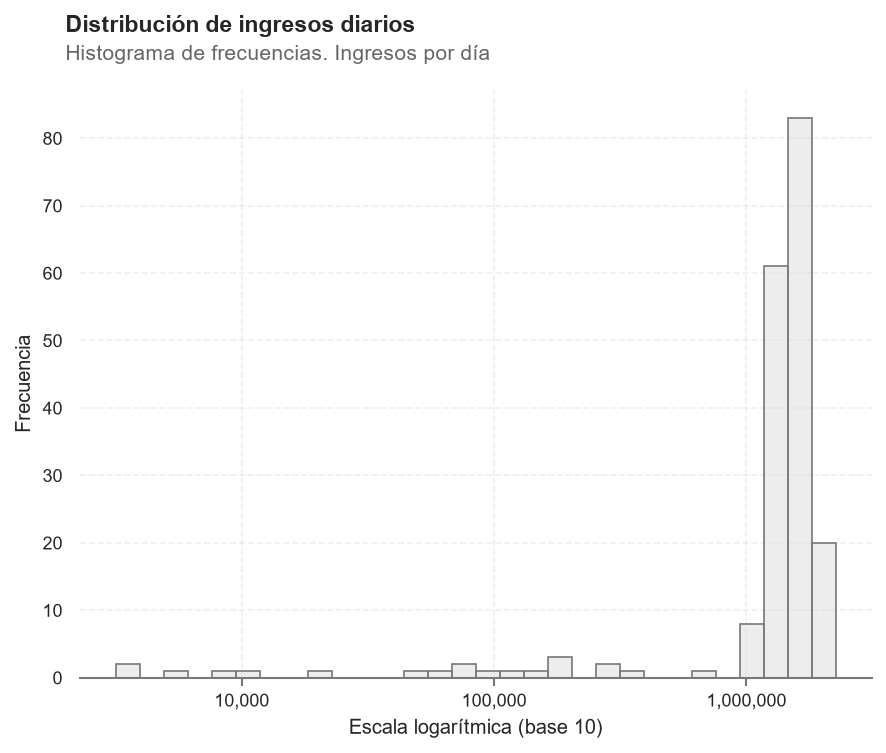

Guardado como: "s_04_07_hist_ingresos_diarios.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_07_hist_ingresos_diarios.png')

In [21]:
fn_01.plot_dist_function_02(
    df_param = df_01.group_by('ordered_on').agg(pl.sum('sales_dollars')),
    df_var = 'sales_dollars',
    bins_param = 30,
    suptitle_param = 'Distribución de ingresos diarios',
    text_param = 'Histograma de frecuencias. Ingresos por día',
    file_param = 's_04_07_hist_ingresos_diarios.png',
    show_param = True)

<h3 style="color:#05856d">4. Análisis relacional</h3>
<hr>

In [22]:
# Variables categóricas
df_01.select( (cs.string() | cs.categorical()) - cs.by_name('product_code') ).glimpse()

# Vriables numéricas y de fecha
df_01.select(cs.numeric() | cs.by_name('ordered_on')).glimpse()

Rows: 1602961
Columns: 4
$ category_name     <cat> 100% AGAVE TEQUILA, IMPORTED SCHNAPPS, 100% AGAVE TEQUILA, 100% AGAVE TEQUILA, AMERICAN CORDIALS & LIQUEUR, AMERICAN SCHNAPPS, AMERICAN VODKAS, AMERICAN VODKAS, AMERICAN VODKAS, AMERICAN VODKAS
$ im_desc           <cat> PATRON SILVER, RUMPLE MINZE PEPPERMINT SCHNAPPS LIQUEUR, DON JULIO BLANCO, PATRON SILVER, 99 WATERMELON PET MINI, 99 FRUITS MINI, BLUE OX VODKA, HAWKEYE VODKA, HAWKEYE VODKA, NEW AMSTERDAM 80PRF
$ period_ordered_on <cat> 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01
$ store_no          <cat> 5444, 5444, 4417, 4417, 4417, 4417, 4417, 4417, 4417, 4417

Rows: 1602961
Columns: 5
$ item_no        <i64> 88296, 69947, 87484, 88296, 84393, 101180, 36875, 36308, 36306, 36968
$ ordered_on    <date> 2026-01-01, 2026-01-01, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02
$ pack           <i64> 12, 12, 12, 12, 1, 1, 6, 6, 12, 24
$ sales_bottles

<h4 style="color:#05856d">4.1. Asociaciones</h4>

Se busca analizar el nivel de asociación basado en la frecuencia u ocurrencia de varaibles categóricas

**¿Exite alguna asociación entre el tipo de presentación (botella) y alguna categoría de acuerdo con la cantidad de producto (botellas) solicitado?**

In [23]:
df_01.get_column('bottle_volume_ml').unique()

bottle_volume_ml
enum
"""20"""
"""25"""
"""50"""
"""100"""
"""200"""
…
"""1125"""
"""1750"""
"""3000"""


In [24]:
# aux = ( df_01
#     .group_by('category_name')
#     .agg(pl.sum('sales_bottles').alias('total_bottles'))
#     .filter( pl.col('total_bottles').rank(method = 'dense', descending = True) <= 3 )
#     .sort( by = ['total_bottles'], descending = [True]) )

# print(aux)

# df_01.\
#     filter(pl.col('category_name').is_in(aux['category_name'].implode())).\
#     group_by(['category_name', 'bottle_volume_ml']).\
#     agg(pl.sum('sales_bottles')).\
#     with_columns( pl.col('bottle_volume_ml').cast(dtype = pl.Float32())).\
#     sort(['bottle_volume_ml','category_name']).\
#     pivot(
#         on = 'category_name',
#         index = 'bottle_volume_ml',
#         values = 'sales_bottles' ).\
#     fill_null(0)

<h4 style="color:#05856d">4.2. Correlaciones</h4>

<h4 style="color:#05856d">4.3. Comparaciones</h4>

<h3 style="color:#05856d">5. Selección del caso de modelamiento</h3>
<hr>

**¿Cuál es el producto que genera más ingresos y que tiene más movimientos?**

De acuerdo al desempeño de los productos agrupados por tienda. El "mejor producto" en términos de ingreso y movimientos es atribuido al código "PRD_001358"

In [25]:
categorias_orden = [
    '0-10 días',
    '10-20 días',
    '20-40 días',
    '40-60 días',
    '60-80 días',
    '80-100 días',
    '100 o más días'
]

analysis_01 = (
    df_01
    .group_by(['product_code'])
    .agg(

        # 1. ¿Qué categorías de productos están involucrados?
        pl.col('category_name').unique().str.join(', '),

        # 2. ¿Cuántas botellas se han vendido en la historia de este producto?
        pl.sum('sales_bottles').alias('volumen_botellas'),

        # 3. Ingresos genereados por la venta de botellas (expresado en miles)
        (pl.sum('sales_dollars')/1000).alias('sales_miles'),
        
        # 4. ¿En cuántos días únicos alguien compró al menos 1 botella?
        pl.n_unique('ordered_on').alias('frecuencia_dias_demanda'),

        # 5 Cantidad de pedidos realizados
        pl.len().alias('pedidos') )

    .with_columns(
        pl.col('frecuencia_dias_demanda')
        .cut(
            breaks=[10, 20, 40, 60, 80, 100],
            labels=categorias_orden,
            left_closed = False )
        .cast(pl.Enum(categorias_orden))
        .alias('frecuencia_dias_demanda_cat') )

    .sort(by = ['pedidos'], descending = True)
    )

print(f"Existen {df_01.n_unique(subset = ['product_code'])} productos únicos en el dataset.")
analysis_01.head()

Existen 4517 productos únicos en el dataset.


product_code,category_name,volumen_botellas,sales_miles,frecuencia_dias_demanda,pedidos,frecuencia_dias_demanda_cat
str,str,i64,f64,u32,u32,enum
"""PRD_002156""","""WHISKEY LIQUEUR""",605911,4089.8705,189,22251,"""100 o más días"""
"""PRD_002146""","""WHISKEY LIQUEUR""",1529401,2294.0965,187,17322,"""100 o más días"""
"""PRD_000205""","""CANADIAN WHISKIES""",247898,4275.48,190,17239,"""100 o más días"""
"""PRD_001437""","""AMERICAN VODKAS""",265058,3975.87,189,15649,"""100 o más días"""
"""PRD_001297""","""AMERICAN VODKAS""",115732,1301.22525,187,15086,"""100 o más días"""


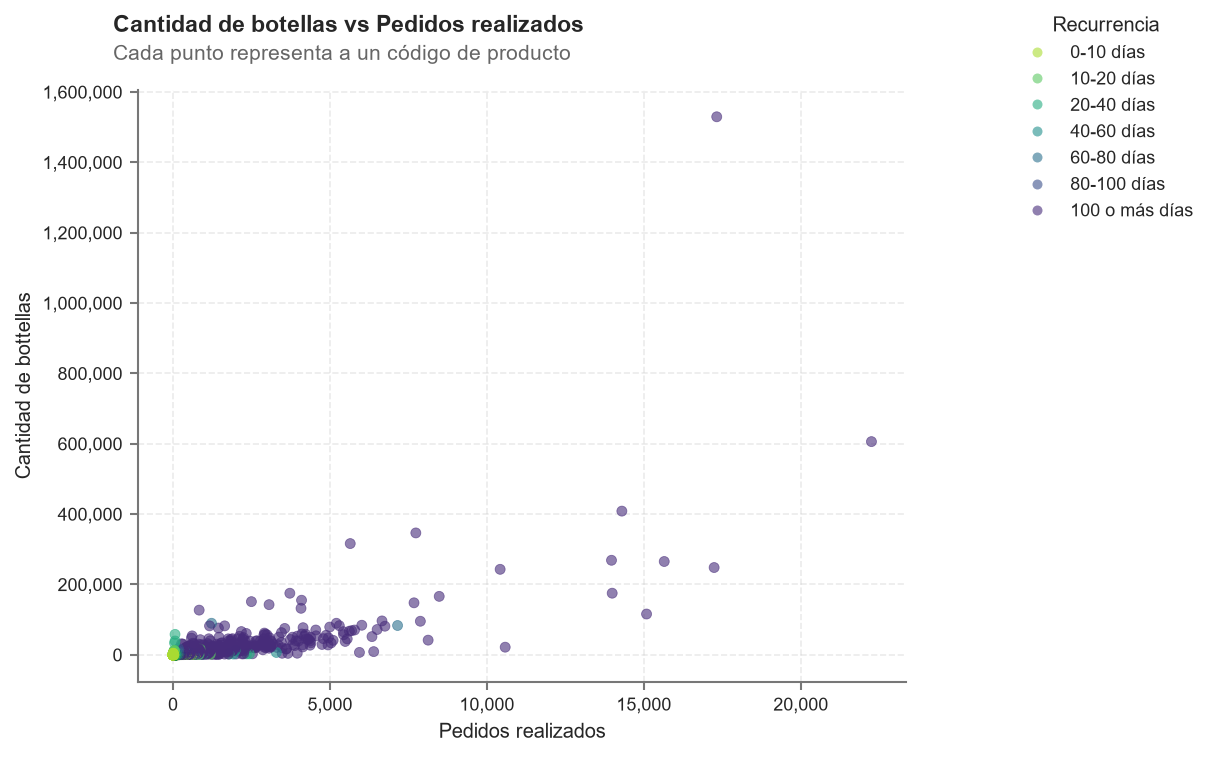

Guardado como: "s_04_08_scatter" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_08_scatter')

In [26]:
fn_01.plot_rel_function_03(
    df_param = analysis_01,
    x_param = 'pedidos',
    x_title_param = 'Pedidos realizados',
    y_param = 'volumen_botellas',
    y_title_param = 'Cantidad de bottellas',
    hue_param = 'frecuencia_dias_demanda_cat',
    hue_tag_param = 'Recurrencia',
    suptitle_param = 'Cantidad de botellas vs Pedidos realizados',
    text_param = 'Cada punto representa a un código de producto',
    file_param = 's_04_08_scatter',
    show_param = True )

Es necesario tomar en cuenta que la cantidad de botellas de pedidas (eje y) es un factor relevante, ya que condiciona la capacidad de manejar altos inventarios para cualquier empresa. El modelo apunta a entrenar un producto con alta frecuencia de pedidos (eje x) y mucha recurrencia delimitada por cuerta capacidad de transporte.    

El producto seleeccionado es el que lleva el código PRD_000201. Se podrá notar que representa un balance razonable entre todos los factores mencionados anteriormente y, además, reporta muchos ingresos para el mayorista.

<h4 style="color:#05856d">5.1. Preparación del caso seleccionado</h4>

In [27]:
df_02 = (
    df_01
    .filter(pl.col('product_code') == 'PRD_000205')
    #.filter(pl.col('product_code') == 'PRD_000201') 
    )

df_02.glimpse()

Rows: 17239
Columns: 11
$ bottle_volume_ml  <enum> 1750, 1750, 1750, 1750, 1750, 1750, 1750, 1750, 1750, 1750
$ category_name      <cat> CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES
$ im_desc            <cat> BLACK VELVET, BLACK VELVET, BLACK VELVET, BLACK VELVET, BLACK VELVET, BLACK VELVET, BLACK VELVET, BLACK VELVET, BLACK VELVET, BLACK VELVET
$ item_no            <i64> 11788, 11788, 11788, 11788, 11788, 11788, 11788, 11788, 11788, 11788
$ ordered_on        <date> 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02
$ pack               <i64> 6, 6, 6, 6, 6, 6, 6, 6, 6, 6
$ period_ordered_on  <cat> 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01
$ product_code       <str> 'PRD_000205', 'PRD_000205', 'PRD_000205', 'PRD_000205', 'PRD_000205

In [28]:
df_02.write_parquet( file = here()/'01_cleaned_data'/'df_02.parquet', 
                     compression = 'zstd',
                     compression_level = 12 )